# Phase 6: Benchmark-relative portfolio construction

Phase 5 found that the signals are weak (3-month ICs of about 0.00–0.03 in the top 50) and that the
baseline's **max-Sharpe optimiser overreacts to weak signals**: a momentum alpha with a standard deviation
of 0.8% a year produced 344% turnover. This notebook replaces it with the standard active-management setup:

1. **A risk model.** A statistical factor model (5 principal components of 3 years of daily returns, plus
   each stock's specific risk) gives the covariance, each stock's **specific (residual) volatility** for
   Grinold's alpha, and a split of active risk into common-factor and stock-specific parts.
2. **A benchmark-relative optimiser.** Each quarter it maximises
   $$h\,\alpha^\top(w-b) \;-\; h\,\lambda\,(w-b)^\top\Sigma\,(w-b) \;-\; \kappa\,c\,\lVert w - w_{\text{current}}\rVert_1$$
   over one quarter ($h = 0.25$), where $b$ is the cap-weighted top 50 (the strategy's own universe),
   $\lambda$ the risk aversion, $c$ = 10 bps the cost per unit traded and $\kappa$ how heavily trading is
   penalised ($\kappa = 1$: at its true cost). Constraints: fully invested, long-only, at most 20% per stock,
   ex-ante tracking error at most 4%.
3. **Alphas from Phase 5**, now scaled by specific volatility: $\alpha_i = 2 \times \text{IC} \times \omega_i \times z_i$,
   with the IC estimated point in time.

**Main settings, and how they were chosen.** $\kappa = 1$ charges trades at their real cost. $\lambda = 10$
comes from Grinold's rule for the optimal tracking error, $\text{TE} \approx \text{IC}\sqrt{N}/\lambda$: for an
IC of about 0.03 across 50 stocks it gives about 2%, a typical enhanced-index budget. The grid of other
settings (section 5) was run at the same time as the main one, so it is reported in full rather than used
to pick a winner.

Because the strategy is now built against the top 50, active statistics are reported **against the
cap-weighted top 50**; the S&P 500 proxy is kept for comparison with earlier phases.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from mts import backtest as bt, config as C, data, optimize as opt, risk, signals as S
from mts import plotting as plot
from mts.plotting import BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, LIGHT_BLUE, INK_2, SURFACE, AXIS, pct_axis

plot.apply_style()
C.RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4f}".format)

def export(df, name):
    """Write a results table to results/<name>.csv so every number in the README can be traced."""
    df.to_csv(C.RESULTS_DIR / f"{name}.csv")
    return df

## 1. Alphas and the risk model

Signals and point-in-time IC estimates are the same as in Phase 5 (`signal-research.ipynb`). The risk model
is refitted on every rebalance date to the 3 years of daily returns before it.

In [2]:
panel = S.load_panel()
top = panel[panel.rank_cap <= C.UNIVERSE_SIZE].copy()
zs = lambda s: top.groupby(level="date")[s].transform(S.winsor_z)
top["composite"] = (zs("mom_12_1") + zs("hist_mean")) / 2
ALPHA_SIGNALS = {"hist_mean": "historical mean", "mom_12_1": "momentum 12-1", "composite": "composite"}
IC_EST = {s: S.PointInTimeIC(S.rank_ic(top, s, "fwd_3m"), horizon_months=3, min_obs=24) for s in ALPHA_SIGNALS}

_models = {}
def model(f):
    """Universe (top 50 caps) and the risk model fitted on the 3 years to f; cached per date."""
    if f not in _models:
        u = data.universe(f)
        _models[f] = (u, risk.fit_pca(data.daily_returns(f, u.index), C.N_FACTORS))
    return _models[f]

def alpha_for(sig, f, tickers, vol):
    ic = IC_EST[sig](f)
    if not np.isfinite(ic):
        return pd.Series(0.0, index=tickers), ic
    return S.grinold_alpha(top.loc[f, sig].reindex(tickers), vol, ic).reindex(tickers).fillna(0), ic

DATES_10 = data.period_ends("2010-01-01", "2023-12-31")
DATES_05 = data.period_ends("2005-01-01", "2023-12-31")
t0 = time.time()
diag_rm = {}
for f in DATES_05:
    u, rm = model(f)
    b = u[rm.tickers] / u[rm.tickers].sum()
    eig = np.diag(rm.F)
    total_var = eig.sum() + rm.D.sum()
    diag_rm[f] = {"stocks": len(rm.tickers), "share of variance in 5 factors": eig.sum() / total_var,
                  "first factor's share": eig[0] / total_var,
                  "median specific vol": np.median(rm.specific_vol), "median total vol": np.median(rm.total_vol),
                  "benchmark vol (model)": np.sqrt(b.values @ rm.cov @ b.values)}
diag_rm = pd.DataFrame(diag_rm).T
print(f"Risk models fitted for {len(diag_rm)} rebalance dates in {time.time() - t0:.0f}s")
export(diag_rm, "phase6_risk_model_by_date").describe().loc[["mean", "min", "max"]]

Risk models fitted for 76 rebalance dates in 1s


,stocks,share of variance in 5 factors,first factor's share,median specific vol,median total vol,benchmark vol (model)
mean,49.4737,0.6311,0.4347,0.1618,0.2590,0.1860
min,47.0000,0.4844,0.2637,0.1207,0.1830,0.1022
max,50.0000,0.7643,0.5670,0.2262,0.3858,0.3091


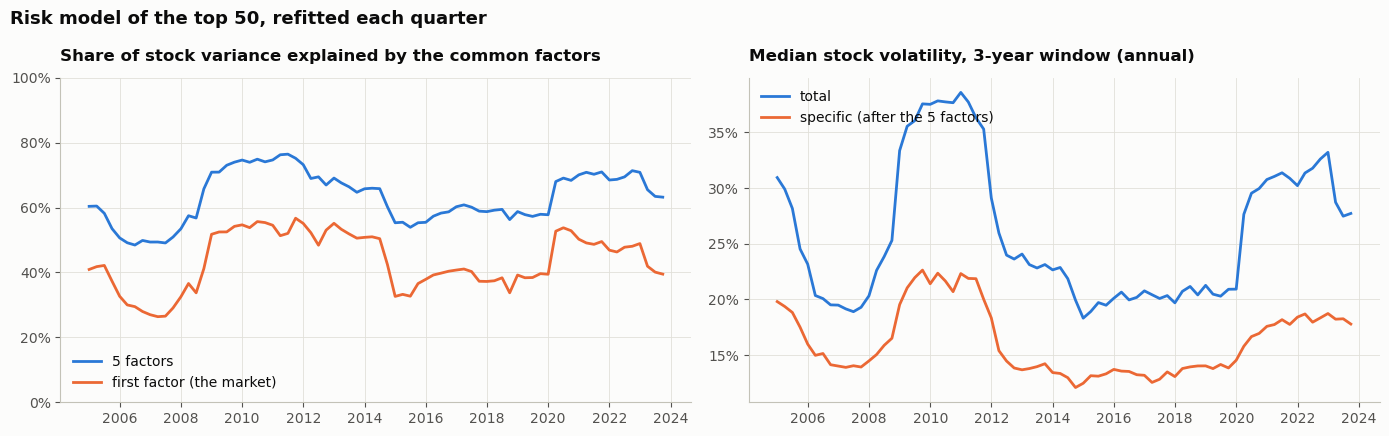

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.4))
ax1.plot(diag_rm.index, diag_rm["share of variance in 5 factors"], color=BLUE, label="5 factors")
ax1.plot(diag_rm.index, diag_rm["first factor's share"], color=ORANGE, label="first factor (the market)")
ax1.yaxis.set_major_formatter(pct_axis); ax1.set_ylim(0, 1)
ax1.set_title("Share of stock variance explained by the common factors")
ax1.legend(loc="lower left")
ax2.plot(diag_rm.index, diag_rm["median total vol"], color=BLUE, label="total")
ax2.plot(diag_rm.index, diag_rm["median specific vol"], color=ORANGE, label="specific (after the 5 factors)")
ax2.yaxis.set_major_formatter(pct_axis)
ax2.set_title("Median stock volatility, 3-year window (annual)")
ax2.legend(loc="upper left")
plot.suptitle(fig, "Risk model of the top 50, refitted each quarter")
plt.tight_layout()
plot.save(fig, "phase6_risk_model")

## 2. The portfolios

`active(signal, λ, κ)` builds the strategy: on each rebalance date, Grinold alphas from specific volatility,
then the optimiser, starting from the drifted holdings so it knows what each trade costs. The diagnostics
record the ex-ante tracking error, how it splits into factor and specific risk, the number of names and the
transfer coefficient.

For comparison, **Phase 5's max-Sharpe allocation** is run with the same alphas (from total volatility, as in Phase 5).

In [4]:
def active(sig, lam=10, kappa=1, te_max=0.04, diag=None):
    def weights(f):
        u, rm = model(f)
        t = rm.tickers
        b = u[t] / u[t].sum()
        a, ic = alpha_for(sig, f, t, rm.specific_vol)
        current = bt.simulate.current
        w = opt.optimize_active(a, rm.cov, b, current if len(current) else None, risk_aversion=lam,
                                te_max=te_max, cost=kappa * C.COST_BPS / 1e4, max_weight=0.20)
        if diag is not None:
            act = w - b
            d = rm.decompose(act)
            diag[f] = {"IC estimate": ic, "alpha sd": a.std(), "ex-ante TE": rm.tracking_error(act),
                       "specific share of active risk": d["specific share"], "names held": int((w > 0.001).sum()),
                       "max active weight": act.abs().max(),
                       "transfer coefficient": S.transfer_coefficient(w, b, a, rm.specific_vol) if a.abs().sum() > 0 else np.nan,
                       "solver ok": bool(w.attrs["success"])}
        return w
    return weights

def max_sharpe_phase5(sig):
    def weights(f):
        u = data.universe(f)
        a, _ = alpha_for(sig, f, list(u.index), top.loc[f, "vol_1y"].reindex(u.index))
        return opt.max_sharpe_with_alpha(f, list(u.index), u, a)["weight"]
    return weights

cap_top50 = lambda f: data.universe(f) / data.universe(f).sum()
cap_sp500 = lambda f: data.universe(f, 10_000) / data.universe(f, 10_000).sum()

def run(portfolios, dates):
    sims = {name: bt.simulate(fn, dates, "2023-12-31") for name, fn in portfolios.items()}
    return {k: v[0] for k, v in sims.items()}, {k: v[1] for k, v in sims.items()}

def table(curves):
    p = bt.performance(curves)[["CAGR", "Volatility", "Sharpe", "Max drawdown", "Turnover / yr"]]
    a = bt.active_stats(curves, "Cap-weight top 50")
    return p.join(a.add_suffix(" vs top 50"))

def show(t):
    pct = [c for c in t if c in ("CAGR", "Volatility", "Max drawdown", "Turnover / yr") or c.startswith(("Active return", "Tracking error"))]
    return t.style.format("{:.1%}", subset=pct).format("{:.2f}", subset=[c for c in t if c not in pct])

## 3. Main result: 2010–2023

Main settings: $\lambda = 10$, $\kappa = 1$, tracking error at most 4%, 10 bps costs.

In [5]:
t0 = time.time()
diags = {s: {} for s in ALPHA_SIGNALS}
MAIN = {f"Active: {label}": active(s, diag=diags[s]) for s, label in ALPHA_SIGNALS.items()}
MAIN.update({"Phase 5 max-Sharpe: historical mean": max_sharpe_phase5("hist_mean"),
             "Phase 5 max-Sharpe: momentum 12-1": max_sharpe_phase5("mom_12_1"),
             "Cap-weight top 50": cap_top50, "Cap-weight S&P 500": cap_sp500})
curves_10, logs_10 = run(MAIN, DATES_10)
main_10 = export(table(curves_10), "phase6_main_2010_2023")
print(f"{time.time() - t0:.0f}s")
show(main_10)

36s


,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Active return vs top 50,Tracking error vs top 50,IR vs top 50,t-stat vs top 50
Active: historical mean,11.8%,18.1%,0.54,-31.3%,28.3%,0.3%,1.6%,0.16,0.61
Active: momentum 12-1,11.6%,17.9%,0.54,-29.5%,25.0%,0.1%,0.8%,0.09,0.34
Active: composite,11.8%,18.1%,0.54,-30.1%,39.6%,0.3%,1.5%,0.20,0.74
Phase 5 max-Sharpe: historical mean,13.3%,22.2%,0.54,-50.5%,144.1%,2.4%,9.4%,0.26,0.97
Phase 5 max-Sharpe: momentum 12-1,9.7%,19.8%,0.42,-32.3%,344.0%,-1.3%,7.6%,-0.17,-0.65
Cap-weight top 50,11.5%,17.9%,0.53,-30.0%,21.9%,0.0%,0.0%,nan,nan
Cap-weight S&P 500,11.1%,17.5%,0.52,-33.6%,7.9%,-0.5%,3.6%,-0.14,-0.51


In [6]:
diag_main = pd.DataFrame({f"Active: {ALPHA_SIGNALS[s]}": pd.DataFrame(d).T.drop(columns="solver ok").astype(float).mean()
                          for s, d in diags.items()}).T
assert all(pd.DataFrame(d).T["solver ok"].all() for d in diags.values()), "an optimisation did not converge"
max_te = max(pd.DataFrame(d).T["ex-ante TE"].max() for d in diags.values())
assert max_te < 0.04 - 1e-4, "the tracking-error cap binds"
print(f"Largest ex-ante tracking error on any date: {max_te:.2%} (cap 4%)")
export(diag_main, "phase6_diagnostics_2010_2023")
diag_main.style.format({"IC estimate": "{:.3f}", "alpha sd": "{:.2%}", "ex-ante TE": "{:.2%}",
                        "specific share of active risk": "{:.0%}", "names held": "{:.1f}",
                        "max active weight": "{:.1%}", "transfer coefficient": "{:.2f}"})

Largest ex-ante tracking error on any date: 2.07% (cap 4%)


,IC estimate,alpha sd,ex-ante TE,specific share of active risk,names held,max active weight,transfer coefficient
Active: historical mean,0.029,1.00%,1.23%,88%,43.5,3.7%,0.72
Active: momentum 12-1,0.003,0.41%,0.55%,89%,47.6,1.1%,0.40
Active: composite,0.023,0.78%,0.91%,86%,44.6,2.2%,0.53


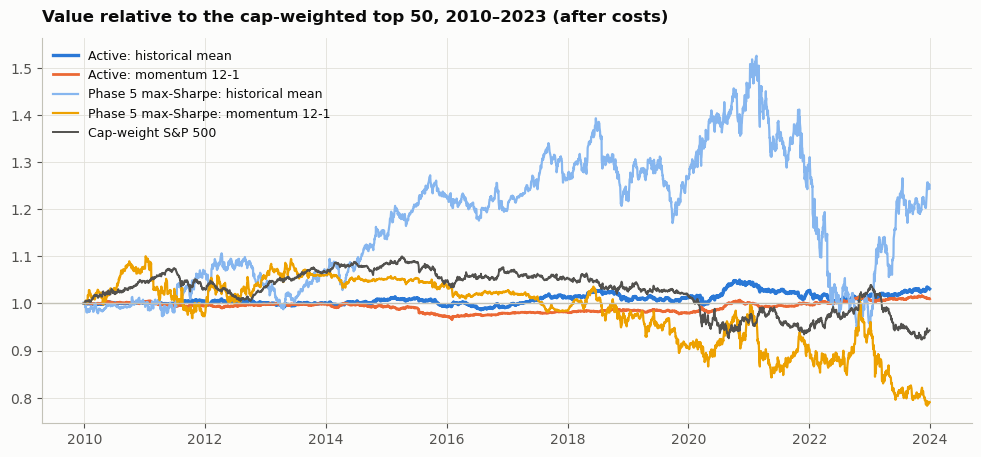

In [7]:
# Growth of $1 relative to the cap-weighted top 50
fig, ax = plt.subplots(figsize=(12, 5))
base = curves_10["Cap-weight top 50"]
for name, color, lw in [("Active: historical mean", BLUE, 2.4), ("Active: momentum 12-1", ORANGE, 2),
                        ("Phase 5 max-Sharpe: historical mean", LIGHT_BLUE, 1.6), ("Phase 5 max-Sharpe: momentum 12-1", YELLOW, 1.6),
                        ("Cap-weight S&P 500", INK_2, 1.4)]:
    rel = curves_10[name] / base
    ax.plot(rel.index, rel.values, color=color, lw=lw, label=name)
ax.axhline(1, color=AXIS, lw=1)
ax.set_title("Value relative to the cap-weighted top 50, 2010–2023 (after costs)")
ax.legend(loc="upper left", fontsize=9)
plot.save(fig, "phase6_relative_value")

## 4. Is the risk model right? Forecast vs realised tracking error

Each quarter's realised active return (strategy minus cap-weighted top 50) is divided by the tracking error
the risk model forecast for that quarter. If the forecasts are right, these standardised returns have a
standard deviation of 1 (the **bias statistic**); with 56 quarters, values between about 0.81 and 1.19 are
consistent with an accurate model. Above that, the model underestimates risk.

In [8]:
def bias_statistic(curve, bench, diag, dates):
    ends = dates[1:] + [curve.index[-1]]
    rows = {}
    for f, g in zip(dates, ends):
        active_q = curve.loc[g] / curve.loc[f] - bench.loc[g] / bench.loc[f]
        horizon = (g - f).days / 365.25
        rows[f] = {"realised active return": active_q, "forecast TE (quarter)": diag[f]["ex-ante TE"] * np.sqrt(horizon)}
    r = pd.DataFrame(rows).T
    r["standardised"] = r["realised active return"] / r["forecast TE (quarter)"]
    return r

bias = {ALPHA_SIGNALS[s]: bias_statistic(curves_10[f"Active: {ALPHA_SIGNALS[s]}"], curves_10["Cap-weight top 50"], diags[s], DATES_10)
        for s in ALPHA_SIGNALS}
band = 1.96 * np.sqrt(1 / (2 * len(DATES_10)))
bias_table = export(pd.DataFrame({k: {"bias statistic": v["standardised"].std(),
                                      "realised TE (annual, from quarters)": v["realised active return"].std() * 2,
                                      "mean forecast TE (annual)": v["forecast TE (quarter)"].mean() * 2,
                                      "quarters": len(v)} for k, v in bias.items()}).T, "phase6_bias_statistic")
print(f"95% band for an accurate model: {1 - band:.2f} to {1 + band:.2f}")
bias_table.style.format({"bias statistic": "{:.2f}", "realised TE (annual, from quarters)": "{:.2%}",
                         "mean forecast TE (annual)": "{:.2%}", "quarters": "{:.0f}"})

95% band for an accurate model: 0.81 to 1.19


,bias statistic,"realised TE (annual, from quarters)",mean forecast TE (annual),quarters
historical mean,1.17,1.59%,1.23%,56
momentum 12-1,1.57,0.86%,0.55%,56
composite,1.32,1.40%,0.91%,56


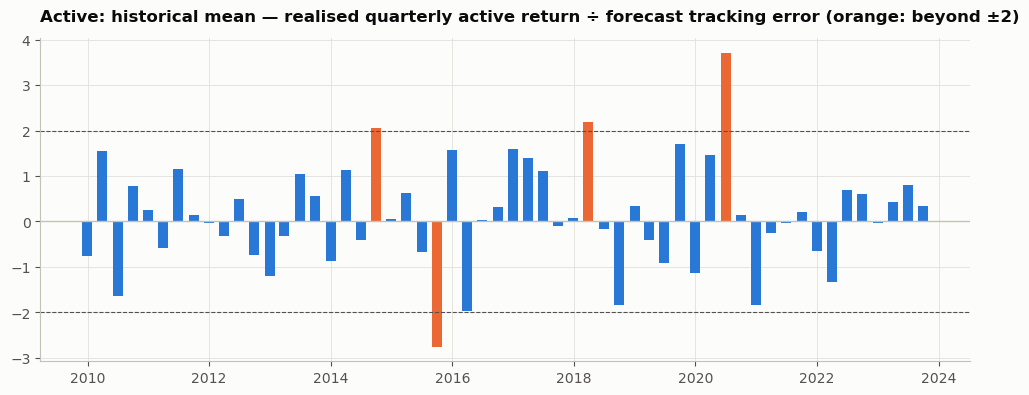

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.2))
b = bias["historical mean"]
ax.bar(b.index, b["standardised"], width=60, color=[BLUE if abs(v) <= 2 else ORANGE for v in b["standardised"]])
for y in (-2, 2):
    ax.axhline(y, color=INK_2, ls="--", lw=0.8)
ax.axhline(0, color=AXIS, lw=1)
ax.set_title("Active: historical mean — realised quarterly active return ÷ forecast tracking error (orange: beyond ±2)")
plot.save(fig, "phase6_bias")

## 5. Sensitivity: risk aversion and trading penalty

Risk aversion $\lambda$ sets how far the portfolio moves from the benchmark; the trading penalty $\kappa$ sets
how readily it trades. Every combination below was run; none is selected after the fact.

In [10]:
t0 = time.time()
LAMBDAS, KAPPAS = [2.5, 5, 10, 20, 40], [0, 1, 3]
GRID = {}
for s in ["hist_mean", "mom_12_1"]:
    for lam in LAMBDAS:
        GRID[(ALPHA_SIGNALS[s], lam, 1)] = active(s, lam=lam, kappa=1)
    for kappa in KAPPAS:
        if kappa != 1:
            GRID[(ALPHA_SIGNALS[s], 10, kappa)] = active(s, lam=10, kappa=kappa)
grid_curves, _ = run({**{k: v for k, v in GRID.items()}, "Cap-weight top 50": cap_top50, "Cap-weight S&P 500": cap_sp500}, DATES_10)
grid = table(grid_curves).drop(index=["Cap-weight top 50", "Cap-weight S&P 500"])
grid.index = pd.MultiIndex.from_tuples(grid.index, names=["signal", "lambda", "kappa"])
export(grid, "phase6_sensitivity_2010_2023")
print(f"{len(GRID)} variants in {time.time() - t0:.0f}s")
show(grid[["Sharpe", "Turnover / yr", "Active return vs top 50", "Tracking error vs top 50", "IR vs top 50", "t-stat vs top 50"]]
     .rename(index=lambda x: f"{x:g}", level="lambda"))

14 variants in 148s


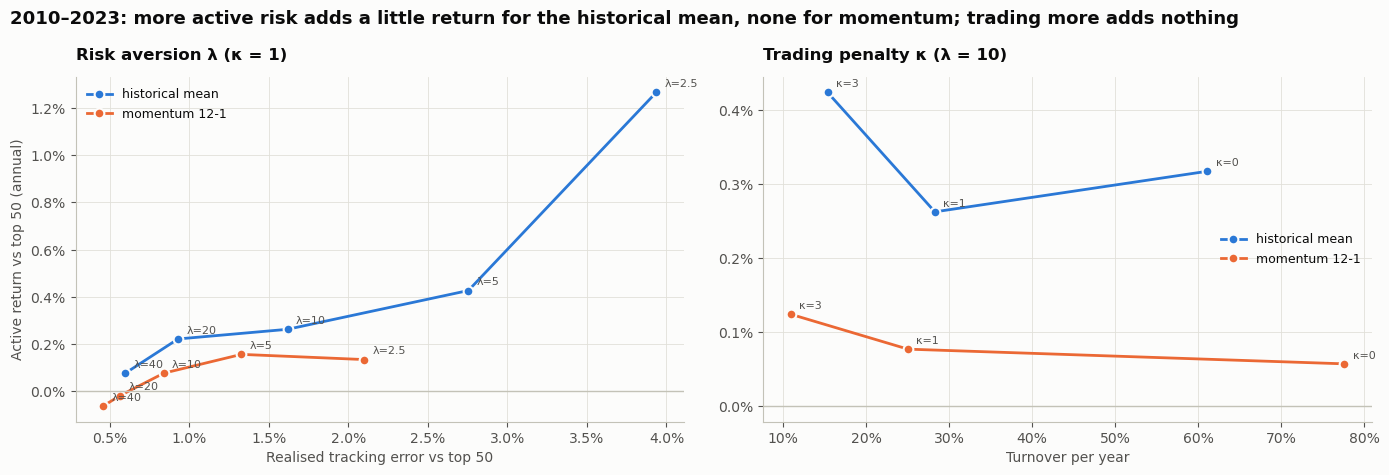

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for sig, color in [("historical mean", BLUE), ("momentum 12-1", ORANGE)]:
    g = grid.loc[sig].xs(1, level="kappa")
    ax1.plot(g["Tracking error vs top 50"], g["Active return vs top 50"], color=color, marker="o", ms=7,
             markeredgecolor=SURFACE, markeredgewidth=1.5, label=sig)
    for lam, row in g.iterrows():
        ax1.annotate(f"λ={lam:g}", (row["Tracking error vs top 50"], row["Active return vs top 50"]),
                     xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK_2)
    k = grid.loc[sig].xs(10, level="lambda").sort_index()
    ax2.plot(k["Turnover / yr"], k["Active return vs top 50"], color=color, marker="o", ms=7,
             markeredgecolor=SURFACE, markeredgewidth=1.5, label=sig)
    for kap, row in k.iterrows():
        ax2.annotate(f"κ={kap:g}", (row["Turnover / yr"], row["Active return vs top 50"]),
                     xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK_2)
for ax in (ax1, ax2):
    ax.axhline(0, color=AXIS, lw=1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0 if ax is ax2 else 1))
ax1.legend(loc="upper left", fontsize=9)
ax2.legend(loc="center right", fontsize=9)
ax1.set_xlabel("Realised tracking error vs top 50"); ax1.set_ylabel("Active return vs top 50 (annual)")
ax1.set_title("Risk aversion λ (κ = 1)")
ax2.set_xlabel("Turnover per year"); ax2.set_title("Trading penalty κ (λ = 10)")
plot.suptitle(fig, "2010–2023: more active risk adds a little return for the historical mean, none for momentum; trading more adds nothing")
plt.tight_layout()
plot.save(fig, "phase6_sensitivity")

## 6. 2005–2023

Adds the 2008 crisis and the 2009 momentum crash. Main settings only.

In [12]:
t0 = time.time()
diags_05 = {s: {} for s in ALPHA_SIGNALS}
P05 = {f"Active: {label}": active(s, diag=diags_05[s]) for s, label in ALPHA_SIGNALS.items()}
P05.update({"Phase 5 max-Sharpe: historical mean": max_sharpe_phase5("hist_mean"),
            "Phase 5 max-Sharpe: momentum 12-1": max_sharpe_phase5("mom_12_1"),
            "Cap-weight top 50": cap_top50, "Cap-weight S&P 500": cap_sp500})
curves_05, _ = run(P05, DATES_05)
main_05 = export(table(curves_05), "phase6_main_2005_2023")
print(f"{time.time() - t0:.0f}s")
show(main_05)

50s


,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Active return vs top 50,Tracking error vs top 50,IR vs top 50,t-stat vs top 50
Active: historical mean,7.7%,19.4%,0.32,-53.4%,29.5%,0.1%,1.5%,0.05,0.20
Active: momentum 12-1,7.6%,19.2%,0.32,-53.8%,48.4%,-0.1%,1.3%,-0.07,-0.29
Active: composite,7.8%,19.3%,0.33,-51.9%,46.5%,0.2%,1.6%,0.12,0.53
Phase 5 max-Sharpe: historical mean,8.5%,22.3%,0.34,-52.6%,172.4%,1.4%,8.9%,0.16,0.68
Phase 5 max-Sharpe: momentum 12-1,4.9%,20.2%,0.19,-57.6%,375.5%,-2.4%,8.0%,-0.30,-1.33
Cap-weight top 50,7.7%,19.2%,0.32,-53.2%,23.9%,0.0%,0.0%,nan,nan
Cap-weight S&P 500,7.6%,19.4%,0.32,-56.0%,9.1%,0.0%,3.5%,0.01,0.04


## 7. Findings

All figures after 10 bps costs, price returns. Active statistics are against the cap-weighted top 50.

**1. The construction problem is solved.** With the same historical-mean alpha as Phase 5, the
benchmark-relative optimiser keeps the Sharpe ratio (0.54) while turnover falls from 144% to 28% a year
(the benchmark itself turns over 22%, from index changes), tracking error from 9.4% to 1.6%, and the maximum
drawdown from −50.5% to −31.3% (benchmark −30.0%). For momentum, turnover falls from 344% to 25% and the
Sharpe ratio rises from 0.42 to 0.54. The portfolios hold 44–48 names on average, the largest active weight
averages 1.1–3.7%, and the transfer coefficient is 0.72 for the historical mean.

**2. That exposes how little the alphas are worth.** Active returns are +0.3% a year for the historical mean
(IR 0.16, t 0.61), +0.1% for momentum (IR 0.09) and +0.3% for the composite (IR 0.20, t 0.74). Since 2005 they
are +0.1%, −0.1% and +0.2%. Phase 5's +2.4% for the historical mean came with 9.4% tracking error and a
−50.5% drawdown, and its information ratio (0.26, t 0.97) is not significant either.

**3. Most active risk is stock-specific (86–89%)**, as intended: the alphas are stock bets, and the
optimiser does not take large bets on the common factors.

**4. The risk model underestimates active risk.** The five factors explain 63% of stock variance on average
(48–76%), the first factor (the market) 43%. But realised tracking error exceeds the forecast: the bias
statistic is 1.17 for the historical mean (just inside the 0.81–1.19 band of an accurate model), 1.32 for the
composite and 1.57 for momentum. *Correction (Phase 7):* this section originally blamed the equally weighted
3-year window and suggested exponential weighting. Phase 7 (`momentum-variants-and-risk.ipynb`) shows that
exponential weighting makes it slightly worse, that the model is accurate for random portfolios (bias 0.98),
and that the cause is misalignment between the alpha and the risk model, plus a few extreme momentum quarters.

**5. Sensitivity** (every setting run, none selected afterwards). For the historical mean, more active risk
earned more: +1.3% a year at 3.9% tracking error with λ = 2.5 (IR 0.32, t 1.20), against +0.1% at λ = 40. For
momentum, active return stays between −0.1% and +0.2% whatever the risk. Tripling the trading penalty (κ = 3)
cuts turnover to 15% and 11% with no loss of return; ignoring costs (κ = 0) more than doubles turnover
(61% and 78%) for nothing. No setting is statistically significant.

**Answer.** Portfolio construction now behaves as theory says it should: risk and costs are controlled and
the signal is expressed as small, diversified tilts. With that fixed, the remaining problem is clear: the
signals carry almost no information (point-in-time ICs of 0.003–0.029), so even a well-built portfolio
earns about the benchmark. Further progress needs better signals or a better risk model, not a different optimiser.

**Limitations**
* Statistical factors stand in for a fundamental risk model; the data has no sector classifications.
* At the main settings the 4% tracking-error cap never binds (the largest ex-ante tracking error on any date is
  printed in section 3); risk aversion does the work.
* Price returns only, constant 3% risk-free rate, linear costs, as in earlier phases.
